# Comparación de modelos — TP3 (Grupo 3)

Notebook para **entender y criticar** los modelos que corrigen el pronóstico de temperatura del NWS.
No entrena nada: lee las salidas que ya dejaron los scripts de `src/` y arma métricas y gráficos.

**Los cuatro modelos** (todos predicen la corrección `c` y el pronóstico corregido es `NWS + c`):

| Nombre | Qué hace |
|---|---|
| **B0 · NWS crudo** | No corrige (`c = 0`). Es la referencia a superar. |
| **B2 · estación × hora** | Suma el error medio histórico de cada estación a cada hora solar. Baseline fuerte. |
| **Ridge** (`lineal`) | Regresión lineal con curvas (splines) sobre 5 familias de variables. Interpretable. |
| **LightGBM** (`lgbm`) | Árboles de gradiente con las mismas variables (sin `station_id`). Es el producto. |

**Cómo se evalúa:** walk-forward con ventana expansiva. Los pliegues 1–2 se usaron para elegir hiperparámetros
y los **pliegues 3–4 (10 días de prueba) son el reporte**: todo lo que sigue, salvo la sección 10, es sobre 3–4.
Convención: **error = observado − pronosticado** (positivo = el pronóstico quedó corto).

**Fuentes:**
- `app/datos/filas.parquet`: una fila por estación × hora objetivo × horizonte con observación real (4,6 M filas), con NWS, Ridge, LightGBM y la observación. No incluye B2.
- `data/resultados/*.csv`: métricas por pliegue (incluyen B2), búsqueda de hiperparámetros, coeficientes y pruebas de significancia. Están fuera de git: para correr esta notebook hay que haber corrido el pipeline (ver README).

> Las métricas de `filas.parquet` usan todas las filas con observación real; las de los CSV usan solo las filas donde B2 está definido. Por eso los MAE pueden diferir en el tercer decimal entre secciones.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import Image, display

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
RES, APP, FIG = RAIZ / "data" / "resultados", RAIZ / "app" / "datos", RAIZ / "figuras"

# mismo estilo que src/interpretar.py (paleta de referencia de la skill dataviz, orden fijo)
COLOR = {"B0": "#2a78d6", "B2": "#eb6834", "lineal": "#1baf7a", "lgbm": "#eda100"}
NOMBRE = {"B0": "NWS crudo (B0)", "B2": "Estación × hora (B2)", "lineal": "Ridge", "lgbm": "LightGBM"}
TXT, TXT2, GRILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "font.size": 9, "figure.dpi": 110,
    "font.family": ["Helvetica Neue", "DejaVu Sans"], "text.color": TXT, "axes.labelcolor": TXT2,
    "axes.edgecolor": GRILLA, "xtick.color": TXT2, "ytick.color": TXT2, "axes.grid": True,
    "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "lines.linewidth": 2,
    "legend.frameon": False, "axes.axisbelow": True})
pd.set_option("display.float_format", "{:.3f}".format)

D = pd.read_parquet(APP / "filas.parquet")
EST = pd.read_parquet(APP / "estaciones.parquet")
D = D.rename(columns={"nws": "B0"})
for m in ("B0", "lineal", "lgbm"):
    D[f"e_{m}"] = D["obs"] - D[m]                     # error de cada modelo
MOD = ["B0", "lineal", "lgbm"]                         # modelos con predicción por fila

POR_PLIEGUE = pd.concat([pd.read_csv(RES / "interpretable_por_pliegue.csv"),
                         pd.read_csv(RES / "lgbm_por_pliegue.csv").query("modelo == 'lgbm'")])
print(f"{len(D):,} filas | {D.station_id.nunique()} estaciones | pliegues {sorted(D.pliegue.unique())} | "
      f"horizontes {D.horizonte.min()}–{D.horizonte.max()} h")

4,619,165 filas | 515 estaciones | pliegues [np.int8(3), np.int8(4)] | horizontes 1–48 h


## 1. Métricas globales

Además del MAE (la métrica con la que se eligió todo), miramos RMSE (castiga errores grandes), sesgo
(error medio: ¿queda una tendencia?), mediana y percentiles altos de |error| (¿la mejora está en las colas o en el centro?).

In [2]:
def metricas(e):
    a = np.abs(e)
    return pd.Series({"MAE": a.mean(), "RMSE": np.sqrt((e**2).mean()), "sesgo": e.mean(),
                      "mediana |e|": np.median(a), "P90 |e|": np.quantile(a, .9), "P99 |e|": np.quantile(a, .99),
                      "% |e| > 3 °C": 100 * (a > 3).mean()})

T = pd.DataFrame({NOMBRE[m]: metricas(D[f"e_{m}"].to_numpy(np.float64)) for m in MOD}).T
T["mejora MAE vs B0 %"] = 100 * (1 - T["MAE"] / T.loc[NOMBRE["B0"], "MAE"])
display(T)

# por pliegue, con B2 desde los CSV (filas donde B2 está definido)
P = (POR_PLIEGUE.query("segmento == 'todas' and horizonte == 'todos'")
     .pivot_table(index="pliegue", columns="modelo", values="MAE")[["B0", "B2", "lineal", "lgbm"]]
     .rename(columns=NOMBRE))
print("MAE por pliegue de reporte (CSV, incluye B2):")
display(P)

,MAE,RMSE,sesgo,mediana |e|,P90 |e|,P99 |e|,% |e| > 3 °C,mejora MAE vs B0 %
NWS crudo (B0),1.544,1.949,-0.021,1.220,3.220,5.000,11.652,0.000
Ridge,1.352,1.732,-0.064,1.110,2.830,4.780,8.202,12.417
LightGBM,1.325,1.706,-0.145,1.080,2.780,4.790,7.833,14.145


MAE por pliegue de reporte (CSV, incluye B2):


modelo,NWS crudo (B0),Estación × hora (B2),Ridge,LightGBM
pliegue,,,,
3,1.555,1.471,1.402,1.382
4,1.532,1.399,1.301,1.267


**Para criticar:** ¿cuánto de la mejora total ya la da B2, que es una tabla de promedios? Mirá también el **sesgo**:
LightGBM queda más sesgado que Ridge y que el propio NWS. Tiene sentido: se eligió con objetivo `regression_l1`, que apunta a la
**mediana** del error y no a la media; minimiza el MAE a costa de un sesgo medio negativo. ¿La mejora de
LightGBM sobre Ridge es del mismo orden que la diferencia entre pliegues? Si el RMSE y el P99 bajan menos que el MAE,
el modelo corrige los errores chicos y deja los grandes.

## 2. Error según el horizonte

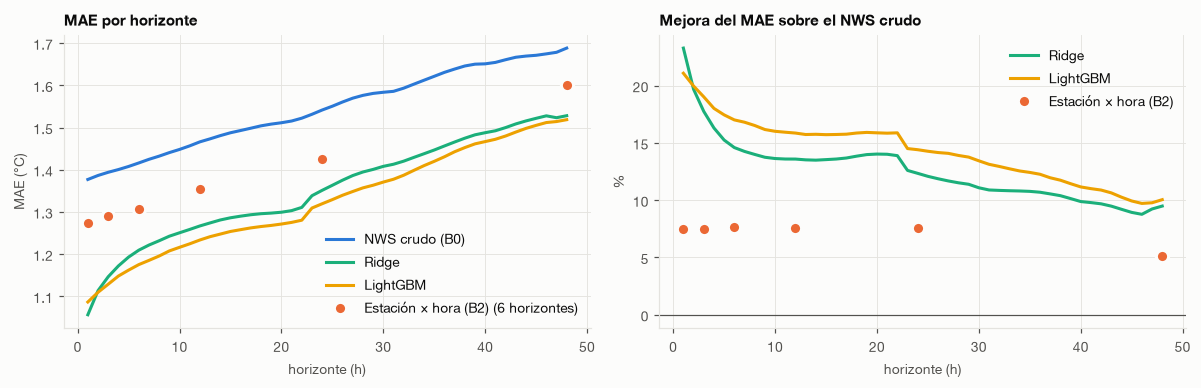

In [3]:
H = D.groupby("horizonte")[[f"e_{m}" for m in MOD]].apply(lambda g: g.abs().mean())
H.columns = MOD
B2h = (POR_PLIEGUE.query("segmento == 'todas' and horizonte != 'todos'")
       .assign(h=lambda x: x.horizonte.astype(int))
       .groupby(["modelo", "h"]).apply(lambda g: np.average(g.MAE, weights=g.n), include_groups=False)
       .unstack(0))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for m in MOD:
    ax[0].plot(H.index, H[m], color=COLOR[m], label=NOMBRE[m])
ax[0].plot(B2h.index, B2h["B2"], "o", color=COLOR["B2"], ms=8, mec=FONDO, mew=2, label=NOMBRE["B2"] + " (6 horizontes)")
ax[0].set(title="MAE por horizonte", xlabel="horizonte (h)", ylabel="MAE (°C)")
ax[0].legend()
for m in ("lineal", "lgbm"):
    ax[1].plot(H.index, 100 * (1 - H[m] / H["B0"]), color=COLOR[m], label=NOMBRE[m])
ax[1].plot(B2h.index, 100 * (1 - B2h["B2"] / B2h["B0"]), "o", color=COLOR["B2"], ms=8, mec=FONDO, mew=2, label=NOMBRE["B2"])
ax[1].axhline(0, color=TXT2, lw=0.8)
ax[1].set(title="Mejora del MAE sobre el NWS crudo", xlabel="horizonte (h)", ylabel="%")
ax[1].legend()
plt.tight_layout(); plt.show()

**Para criticar:** hay un escalón en ~22 h en las dos curvas de los modelos: ¿qué variable deja de estar disponible
(o cambia de significado) a partir de ese horizonte? La ventaja de los modelos sobre B2 se concentra en los primeros horizontes (ahí sirve el
error reciente de la estación). A horizontes largos, ¿los modelos agregan algo más que el sesgo por estación y hora?

## 3. ¿Las diferencias son reales o ruido?

Con 4,6 M filas cualquier diferencia parece significativa, pero las filas de un mismo día **no son independientes**
(comparten el mismo tiempo meteorológico). La unidad honesta es el **día de prueba**: 10 días (5 con historia completa
y 5 con historia incompleta). Prueba t pareada sobre la diferencia diaria de MAE (Diebold–Mariano con pérdida absoluta)
y bootstrap por días para el IC 95 %.

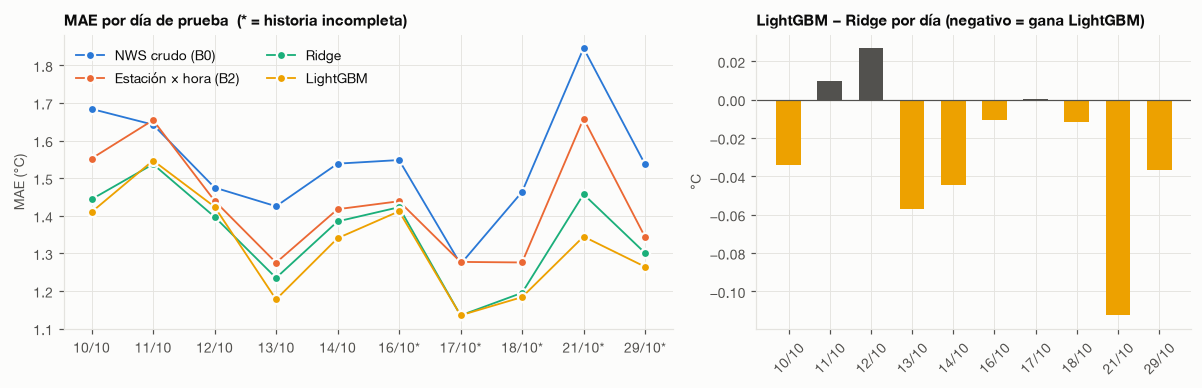

,segmento,A,B,dias,dif_media_C,IC95_inf,IC95_sup,t,p_valor,dias_gana_A
0,todas,lgbm,lineal,10,-0.027,-0.052,-0.005,-2.154,0.060,7
1,todas,lineal,B2,10,-0.082,-0.118,-0.050,-4.407,0.002,10
2,todas,lgbm,B2,10,-0.109,-0.164,-0.067,-4.173,0.002,10
3,todas,B2,B0,10,-0.110,-0.154,-0.062,-4.440,0.002,8
4,completa,lgbm,lineal,5,-0.020,-0.048,0.009,-1.223,0.288,3
5,completa,lineal,B2,5,-0.068,-0.099,-0.038,-3.725,0.020,5
6,completa,lgbm,B2,5,-0.088,-0.122,-0.051,-4.212,0.014,5
7,completa,B2,B0,5,-0.085,-0.137,-0.026,-2.721,0.053,4
8,incompleta,lgbm,lineal,5,-0.034,-0.075,-0.007,-1.671,0.170,4
9,incompleta,lineal,B2,5,-0.097,-0.154,-0.040,-2.863,0.046,5


In [4]:
DIA = pd.read_csv(RES / "comparacion_por_dia.csv")
DIA["fecha"] = pd.to_datetime(DIA["dia"], format="%Y_%m_%d").dt.strftime("%d/%m")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
x = np.arange(len(DIA))
for m in ("B0", "B2", "lineal", "lgbm"):
    ax[0].plot(x, DIA[m], "-o", color=COLOR[m], lw=1.2, ms=6, mec=FONDO, mew=1.5, label=NOMBRE[m])
ax[0].set_xticks(x, DIA["fecha"] + np.where(DIA["historia"] == "incompleta", "*", ""))
ax[0].set(title="MAE por día de prueba  (* = historia incompleta)", ylabel="MAE (°C)")
ax[0].legend(ncol=2)
d = DIA["lgbm"] - DIA["lineal"]
ax[1].bar(x, d, color=np.where(d < 0, COLOR["lgbm"], TXT2), width=0.6)
ax[1].axhline(0, color=TXT2, lw=0.8)
ax[1].set_xticks(x, DIA["fecha"], rotation=45)
ax[1].set(title="LightGBM − Ridge por día (negativo = gana LightGBM)", ylabel="°C")
plt.tight_layout(); plt.show()

display(pd.read_csv(RES / "comparacion_significancia.csv"))

**Para criticar:** ¿qué tan robusta es una conclusión con 10 días? Una diferencia de 0,02–0,03 °C puede ser real pero
chica frente a la variación entre días (que es de décimas). Fijate cuántos días gana cada modelo y si el IC cruza el 0.

## 4. Distribución del error

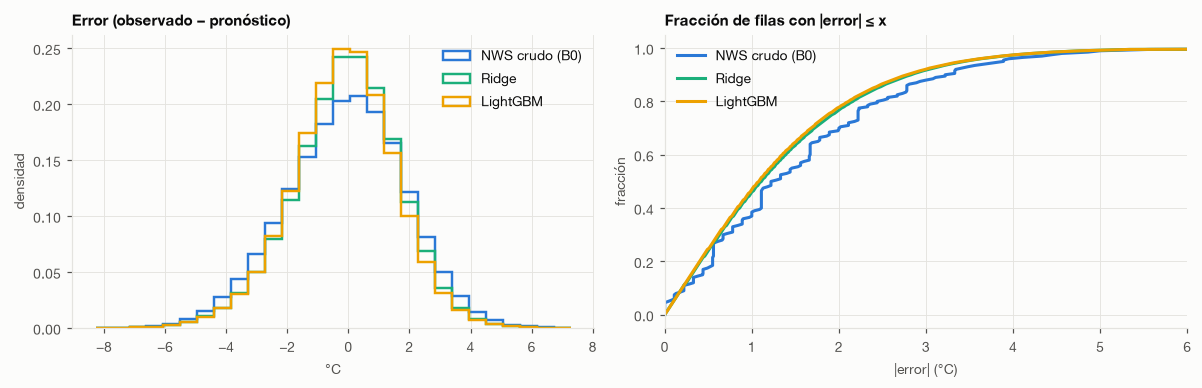

Ridge    : mejora 55.4 % de las filas, empeora 39.1 % (empeora > 1 °C: 5.7 %)
LightGBM : mejora 55.8 % de las filas, empeora 39.2 % (empeora > 1 °C: 7.1 %)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.arange(-8, 8 + 1e-9, 5 / 9) - 5 / 18     # bins de 1 °F: el NWS pronostica en °F enteros
for m in MOD:
    ax[0].hist(D[f"e_{m}"], bins=bins, histtype="step", lw=1.6, density=True, color=COLOR[m], label=NOMBRE[m])
ax[0].set(title="Error (observado − pronóstico)", xlabel="°C", ylabel="densidad")
ax[0].legend()
q = np.linspace(0, 1, 201)
for m in MOD:
    ax[1].plot(np.quantile(np.abs(D[f"e_{m}"]), q), q, color=COLOR[m], label=NOMBRE[m])
ax[1].set(title="Fracción de filas con |error| ≤ x", xlabel="|error| (°C)", ylabel="fracción", xlim=(0, 6))
ax[1].legend()
plt.tight_layout(); plt.show()

# fila a fila: ¿cuántas veces la corrección empeora el pronóstico?
for m in ("lineal", "lgbm"):
    d = np.abs(D[f"e_{m}"]) - np.abs(D["e_B0"])
    print(f"{NOMBRE[m]:9s}: mejora {100*(d < -0.05).mean():.1f} % de las filas, empeora {100*(d > 0.05).mean():.1f} % "
          f"(empeora > 1 °C: {100*(d > 1).mean():.1f} %)")

El NWS pronostica en **°F enteros**, por eso su error sale «escalonado» (saltos de 5/9 °C); los modelos suman una
corrección continua y suavizan la distribución.

**Para criticar:** el modelo corrige en promedio, pero empeora una fracción grande de filas individuales.
LightGBM empeora en más de 1 °C más filas que Ridge: corrige más fuerte y a veces se equivoca más fuerte.
¿Es aceptable para un usuario que mira **una** estación y **una** hora? Eso es lo que justifica la banda de confianza (sección 11).

## 5. Según la condición del tiempo pronosticada

,NWS crudo (B0),Ridge,LightGBM,n,mejora Ridge %,mejora LightGBM %
condicion,,,,,,
despejado,1.560,1.277,1.225,2344955,18.125,21.472
lluvia,1.540,1.480,1.517,787777,3.924,1.504
nublado,1.484,1.376,1.373,570950,7.241,7.473
parcial,1.538,1.413,1.377,484140,8.131,10.430
tormenta,1.604,1.464,1.461,238293,8.738,8.913
niebla,1.469,1.458,1.440,104519,0.706,1.955
otro,1.471,1.251,1.200,75610,14.980,18.437
nieve,1.537,1.407,1.055,12921,8.427,31.343


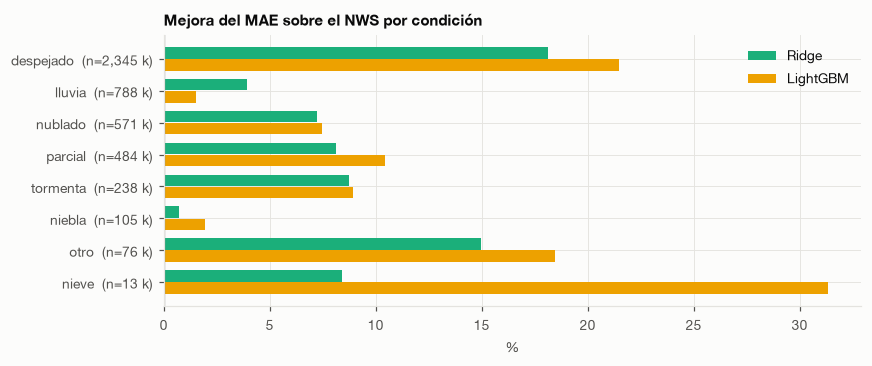

In [6]:
G = D.groupby("condicion", observed=True)
Tc = pd.DataFrame({NOMBRE[m]: G[f"e_{m}"].apply(lambda e: e.abs().mean()) for m in MOD})
Tc["n"] = G.size()
for m in ("lineal", "lgbm"):
    Tc[f"mejora {NOMBRE[m]} %"] = 100 * (1 - Tc[NOMBRE[m]] / Tc[NOMBRE["B0"]])
Tc = Tc.sort_values("n", ascending=False)
display(Tc)

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(Tc))
for i, m in enumerate(("lineal", "lgbm")):
    ax.barh(y + (i - 0.5) * 0.38, Tc[f"mejora {NOMBRE[m]} %"], height=0.36, color=COLOR[m], label=NOMBRE[m])
ax.set_yticks(y, [f"{c}  (n={n/1e3:,.0f} k)" for c, n in zip(Tc.index, Tc["n"])])
ax.invert_yaxis(); ax.axvline(0, color=TXT2, lw=0.8)
ax.set(title="Mejora del MAE sobre el NWS por condición", xlabel="%")
ax.legend(); plt.tight_layout(); plt.show()

Ojo con los grupos chicos: «nieve» tiene 13 k filas de pocos episodios; su 31 % no es generalizable.

**Para criticar:** con lluvia el modelo casi no ayuda (y LightGBM menos que Ridge). ¿Falta información
(no tenemos precipitación pronosticada en cantidad, solo probabilidad), o es que el error con lluvia es menos predecible?

## 6. Según la hora solar local

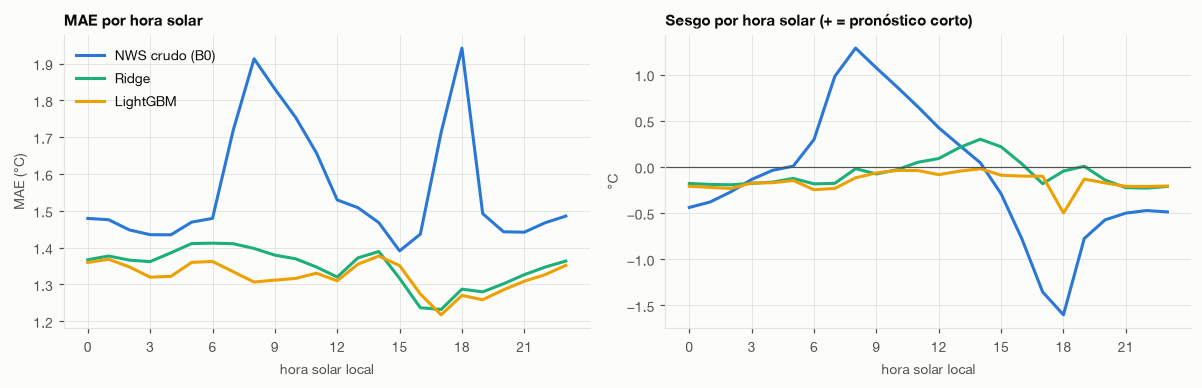

In [7]:
G = D.groupby("hora_solar")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for m in MOD:
    ax[0].plot(G[f"e_{m}"].apply(lambda e: e.abs().mean()), color=COLOR[m], label=NOMBRE[m])
    ax[1].plot(G[f"e_{m}"].mean(), color=COLOR[m], label=NOMBRE[m])
ax[0].set(title="MAE por hora solar", xlabel="hora solar local", ylabel="MAE (°C)", xticks=range(0, 24, 3))
ax[1].axhline(0, color=TXT2, lw=0.8)
ax[1].set(title="Sesgo por hora solar (+ = pronóstico corto)", xlabel="hora solar local", ylabel="°C", xticks=range(0, 24, 3))
ax[0].legend(); plt.tight_layout(); plt.show()

**Para criticar:** el NWS tiene un sesgo diurno marcado que los modelos casi eliminan. Lo que queda, ¿es un sesgo
que todavía se podría corregir o es ruido? Mirá si el MAE corregido sigue teniendo un pico en alguna franja horaria.

## 7. Por estación

estaciones donde LightGBM empeora el MAE: 35 de 515 | mediana de la mejora: 13.3 %


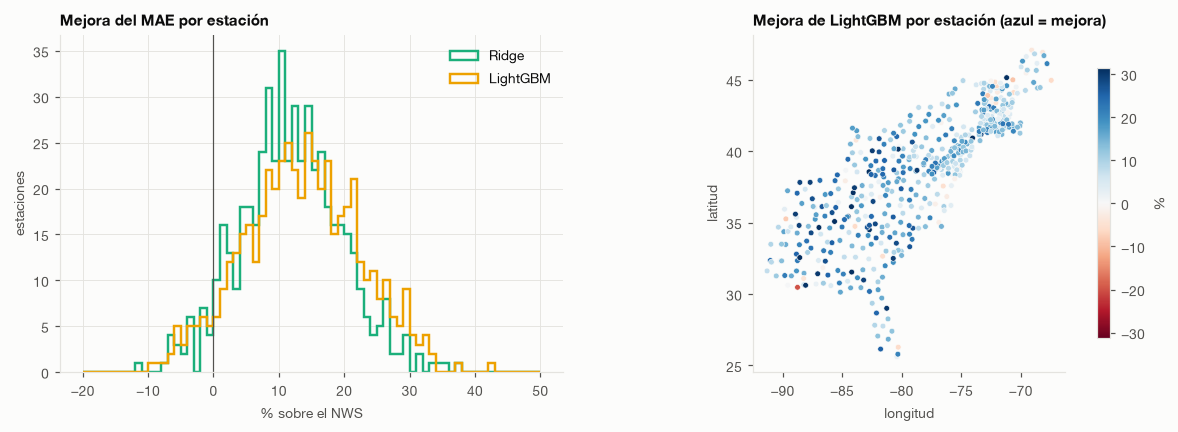

Las 10 estaciones donde LightGBM menos ayuda:


,estado,n,B0,lineal,lgbm,mejora_lgbm
station_id,,,,,,
TFBM6,MS,475,1.792,1.634,2.151,-20.034
K8B0,ME,9282,1.363,1.356,1.486,-9.031
LSC07,VT,8911,1.678,1.620,1.816,-8.225
E6329,TN,7621,1.309,1.404,1.413,-7.938
KCDA,VT,10098,1.380,1.367,1.474,-6.840
F7903,ME,8954,1.525,1.447,1.617,-6.077
D8542,ME,9056,1.133,1.121,1.200,-5.957
GA340,GA,9014,1.378,1.533,1.460,-5.935
1359W,FL,8576,0.895,0.887,0.947,-5.793


In [8]:
S = D.groupby("station_id", observed=True)[[f"e_{m}" for m in MOD]].apply(lambda g: g.abs().mean())
S.columns = MOD
S["n"] = D.groupby("station_id", observed=True).size()
S = S.join(EST.set_index("station_id"))
for m in ("lineal", "lgbm"):
    S[f"mejora_{m}"] = 100 * (1 - S[m] / S["B0"])
print(f"estaciones donde LightGBM empeora el MAE: {(S.mejora_lgbm < 0).sum()} de {len(S)} | "
      f"mediana de la mejora: {S.mejora_lgbm.median():.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.25]})
b = np.linspace(-20, 50, 71)
for m in ("lineal", "lgbm"):
    ax[0].hist(S[f"mejora_{m}"], bins=b, histtype="step", lw=1.6, color=COLOR[m], label=NOMBRE[m])
ax[0].axvline(0, color=TXT2, lw=0.8)
ax[0].set(title="Mejora del MAE por estación", xlabel="% sobre el NWS", ylabel="estaciones")
ax[0].legend()
lim = np.nanpercentile(np.abs(S.mejora_lgbm), 98)
sc = ax[1].scatter(S.lon, S.lat, c=S.mejora_lgbm, cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim), s=14,
                   edgecolor=FONDO, linewidth=0.4)
ax[1].set(title="Mejora de LightGBM por estación (azul = mejora)", xlabel="longitud", ylabel="latitud", aspect=1.2)
ax[1].grid(False)
fig.colorbar(sc, ax=ax[1], label="%", shrink=0.8)
plt.tight_layout(); plt.show()

print("Las 10 estaciones donde LightGBM menos ayuda:")
display(S.sort_values("mejora_lgbm")[["estado", "n", "B0", "lineal", "lgbm", "mejora_lgbm"]].head(10))

Mirá la columna `n`: una estación con pocas filas (pocos días con observación) puede salir mal por azar.

**Para criticar:** ¿las estaciones donde el modelo empeora tienen algo en común (estado, costa, montaña, pocas filas)?
El modelo no ve `station_id`: si una estación se comporta distinto del resto y no tiene historia, el modelo no tiene cómo saberlo.

## 8. Historia completa vs incompleta

In [9]:
Th = D.groupby("historia", observed=True)[[f"e_{m}" for m in MOD]].apply(lambda g: g.abs().mean())
Th.columns = [NOMBRE[m] for m in MOD]
Th["n"] = D.groupby("historia", observed=True).size()
for m in ("lineal", "lgbm"):
    Th[f"mejora {NOMBRE[m]} %"] = 100 * (1 - Th[NOMBRE[m]] / Th[NOMBRE["B0"]])
display(Th)

,NWS crudo (B0),Ridge,LightGBM,n,mejora Ridge %,mejora LightGBM %
historia,,,,,,
completa,1.555,1.402,1.382,2332628,9.858,11.124
incompleta,1.532,1.301,1.267,2286537,15.068,17.274


«Historia incompleta» = día válido al que le falta (o se le excluyó) alguno de los 3 días de calendario previos,
así que parte de sus variables con memoria (rezagos) están vacías. La marca no excluye el día. **Para criticar:** el segmento con historia completa es el que representa
la operación normal; ahí se ven las diferencias reales entre modelos.

## 9. ¿Ridge y LightGBM aprenden lo mismo?

Si las dos correcciones están muy correlacionadas, LightGBM es básicamente un Ridge un poco más flexible.
Además miramos la **calibración de la corrección**: si el modelo dice «sumá +1 °C», ¿el error real era +1 °C?
La diagonal es la calibración perfecta; una pendiente menor que 1 significa que el modelo corrige de menos (prudente).

correlación entre las correcciones: 0.826 | desvío de la corrección: Ridge 0.90 °C, LightGBM 1.03 °C | desvío del error del NWS: 1.95 °C


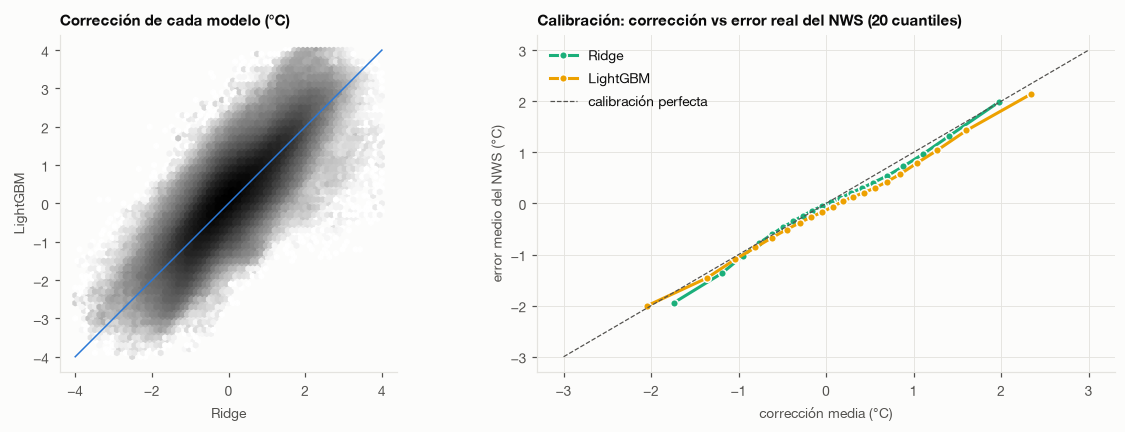

In [10]:
cl, cg = D["lineal"] - D["B0"], D["lgbm"] - D["B0"]
print(f"correlación entre las correcciones: {np.corrcoef(cl, cg)[0, 1]:.3f} | "
      f"desvío de la corrección: Ridge {cl.std():.2f} °C, LightGBM {cg.std():.2f} °C | "
      f"desvío del error del NWS: {D.e_B0.std():.2f} °C")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hb = ax[0].hexbin(cl, cg, gridsize=70, extent=(-4, 4, -4, 4), bins="log", cmap="Greys", mincnt=1)
ax[0].plot([-4, 4], [-4, 4], color=COLOR["B0"], lw=1)
ax[0].set(title="Corrección de cada modelo (°C)", xlabel="Ridge", ylabel="LightGBM", aspect="equal")
ax[0].grid(False)
for m, c in (("lineal", cl), ("lgbm", cg)):
    k = pd.qcut(c, 20, duplicates="drop")
    g = pd.DataFrame({"c": c, "e": D["e_B0"]}).groupby(k, observed=True).mean()
    ax[1].plot(g["c"], g["e"], "-o", color=COLOR[m], ms=5, mec=FONDO, label=NOMBRE[m])
ax[1].plot([-3, 3], [-3, 3], color=TXT2, lw=0.8, ls="--", label="calibración perfecta")
ax[1].set(title="Calibración: corrección vs error real del NWS (20 cuantiles)",
          xlabel="corrección media (°C)", ylabel="error medio del NWS (°C)")
ax[1].legend(); plt.tight_layout(); plt.show()

**Para criticar:** la corrección tiene un desvío mucho menor que el error del NWS: el modelo solo predice una parte
del error. Si la curva de calibración queda sobre la diagonal en los extremos, el modelo podría corregir más fuerte
en esos casos.

## 10. Elección de hiperparámetros y estabilidad entre pliegues

Los hiperparámetros se eligieron en los pliegues 1–2. Si el modelo está sobreajustado a esa elección, la mejora relativa
caería en 3–4. Comparamos la **mejora relativa** (no el MAE absoluto, porque cada semana es más o menos difícil para el NWS).

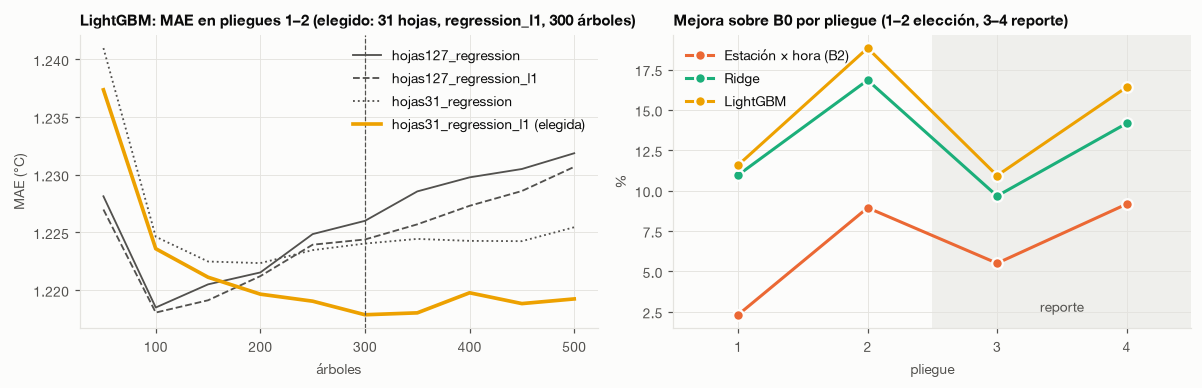

MAE por pliegue:


,B0,B2,lineal,lgbm
pliegue,,,,
1,1.386,1.354,1.234,1.226
2,1.491,1.358,1.240,1.210
3,1.552,1.467,1.402,1.382
4,1.516,1.377,1.301,1.267


In [11]:
E = pd.read_csv(RES / "lgbm_eleccion.csv").query("segmento == 'todas'")
E = E.groupby(["config", "arboles"]).apply(lambda g: np.average(g.MAE, weights=g.n), include_groups=False).unstack(0)
hp = json.loads((RES / "lgbm_hiperparametros.json").read_text())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
elegida = f"hojas{hp['num_leaves']}_{hp['objective']}"
for c, ls in zip(E.columns, ["-", "--", ":", "-."]):
    ax[0].plot(E.index, E[c], color=COLOR["lgbm"] if c == elegida else TXT2, ls="-" if c == elegida else ls,
               lw=2.4 if c == elegida else 1.2, label=c + (" (elegida)" if c == elegida else ""))
ax[0].axvline(hp["arboles"], color=TXT2, lw=0.8, ls="--")
ax[0].set(title=f"LightGBM: MAE en pliegues 1–2 (elegido: {hp['num_leaves']} hojas, {hp['objective']}, {hp['arboles']} árboles)",
          xlabel="árboles", ylabel="MAE (°C)")
ax[0].legend()

B = pd.read_csv(RES / "baselines_por_pliegue.csv").query("segmento == 'todas' and universo == 'reales' and horizonte == 'todos'")
b0 = B.query("baseline == 'B0'").set_index("pliegue")["MAE"]
b2 = B.query("baseline == 'B2'").set_index("pliegue")["MAE"]
eleg = {"lgbm": E[f"hojas{hp['num_leaves']}_{hp['objective']}"].loc[hp["arboles"]]}
IE = pd.read_csv(RES / "interpretable_eleccion.csv").query("segmento == 'todas'")
sesgo = json.loads((RES / "interpretable_hiperparametros.json").read_text())["sesgo"]
lin12 = IE[IE.sesgo == sesgo].set_index("pliegue")["MAE"]
gbm12 = (pd.read_csv(RES / "lgbm_eleccion.csv")
         .query(f"segmento == 'todas' and config == 'hojas{hp['num_leaves']}_{hp['objective']}' and arboles == {hp['arboles']}")
         .set_index("pliegue")["MAE"])
rep = POR_PLIEGUE.query("segmento == 'todas' and horizonte == 'todos'").pivot_table(index="pliegue", columns="modelo", values="MAE")
M = pd.DataFrame({"B0": b0, "B2": b2, "lineal": pd.concat([lin12, rep["lineal"]]), "lgbm": pd.concat([gbm12, rep["lgbm"]])})
R = 100 * (1 - M[["B2", "lineal", "lgbm"]].div(M["B0"], axis=0))
for m in R:
    ax[1].plot(R.index, R[m], "-o", color=COLOR[m], ms=7, mec=FONDO, mew=1.5, label=NOMBRE[m])
ax[1].axvspan(2.5, 4.5, color=GRILLA, alpha=0.5, lw=0)
ax[1].text(3.5, R.values.min(), "reporte", ha="center", va="bottom", color=TXT2)
ax[1].set(title="Mejora sobre B0 por pliegue (1–2 elección, 3–4 reporte)", xlabel="pliegue", ylabel="%", xticks=[1, 2, 3, 4], xlim=(0.5, 4.5))
ax[1].legend(); plt.tight_layout(); plt.show()
print("MAE por pliegue:"); display(M)

**Para criticar:** si la curva de árboles es plana alrededor del elegido, la elección no importa mucho (bueno: no hay
sobreajuste fino). Ojo: el MAE de B0 en los pliegues 1–2 no sale exactamente de las mismas filas que el de los modelos;
la comparación justa es la del mismo pliegue.

## 11. Qué usa cada modelo

Ridge: coeficientes estandarizados en los dos pliegues de reporte. Si un coeficiente cambia mucho de signo o tamaño
entre pliegues, su interpretación no es confiable. LightGBM: importancia por ganancia (proporción).

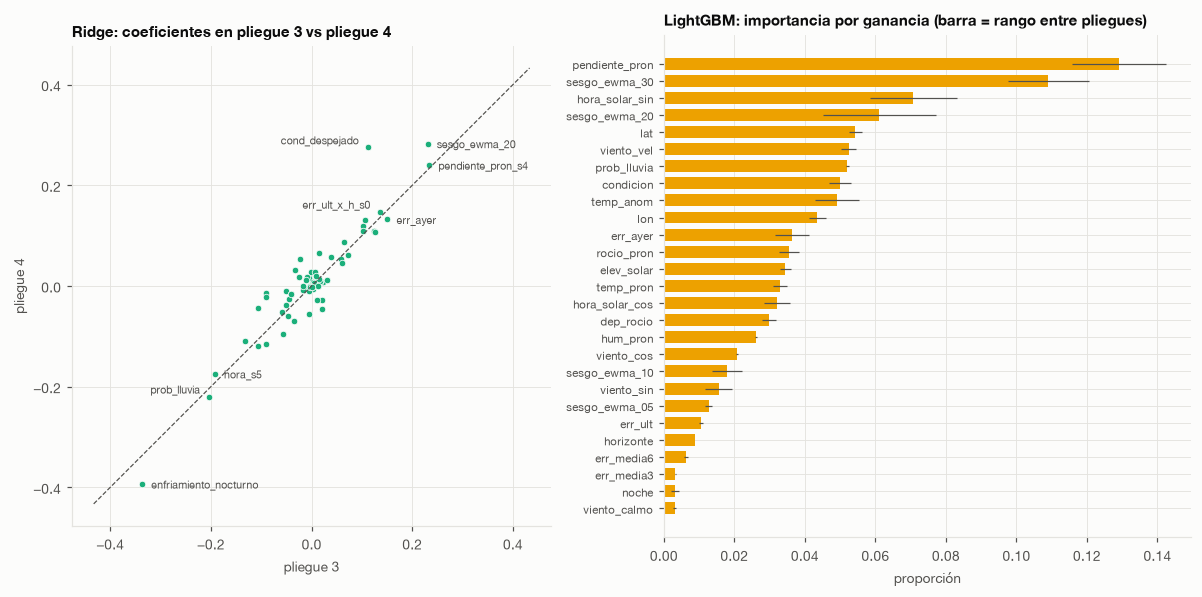

correlación de coeficientes Ridge entre pliegues: 0.933


In [12]:
CO = pd.read_csv(RES / "interpretable_coeficientes.csv", index_col=0)
IM = pd.read_csv(RES / "lgbm_importancia.csv", index_col=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].scatter(CO.pliegue_3, CO.pliegue_4, s=18, color=COLOR["lineal"], edgecolor=FONDO, linewidth=0.5)
lim = np.abs(CO.values).max() * 1.1
ax[0].plot([-lim, lim], [-lim, lim], color=TXT2, lw=0.8, ls="--")
IZQ = {"cond_despejado", "err_ult_x_h_s0", "prob_lluvia"}       # etiquetas a la izquierda del punto (evita choques)
for n, r in CO.assign(t=CO.abs().max(axis=1)).nlargest(8, "t").iterrows():
    ax[0].annotate(n, (r.pliegue_3, r.pliegue_4), fontsize=7, color=TXT2, textcoords="offset points",
                   xytext=(-6, 2) if n in IZQ else (6, -3), ha="right" if n in IZQ else "left")
ax[0].set(title="Ridge: coeficientes en pliegue 3 vs pliegue 4", xlabel="pliegue 3", ylabel="pliegue 4", aspect="equal")
I = IM.assign(media=IM.mean(axis=1)).sort_values("media")
y = np.arange(len(I))
ax[1].barh(y, I.media, color=COLOR["lgbm"], height=0.7)
ax[1].errorbar(I.media, y, xerr=np.abs(I[["pliegue_3", "pliegue_4"]].sub(I.media, axis=0)).max(axis=1),
               fmt="none", ecolor=TXT2, lw=0.8)
ax[1].set_yticks(y, I.index, fontsize=7.5)
ax[1].set(title="LightGBM: importancia por ganancia (barra = rango entre pliegues)", xlabel="proporción")
plt.tight_layout(); plt.show()
print(f"correlación de coeficientes Ridge entre pliegues: {np.corrcoef(CO.pliegue_3, CO.pliegue_4)[0,1]:.3f}")

**Para criticar:** LightGBM usa mucho `lat` y `lon`. ¿Está aprendiendo geografía física o está identificando estaciones
de manera encubierta? La Etapa B lo analizó (figura `interp_latlon.png`, abajo): lat/lon correlaciona 0,27 con el sesgo
histórico por estación contra 0,80 de los sesgos EWMA. Ojo también con la importancia por ganancia: favorece variables continuas con muchos cortes posibles.

Figuras de la Etapa B (generadas por `src/interpretar.py`):

interp_curvas_ridge.png


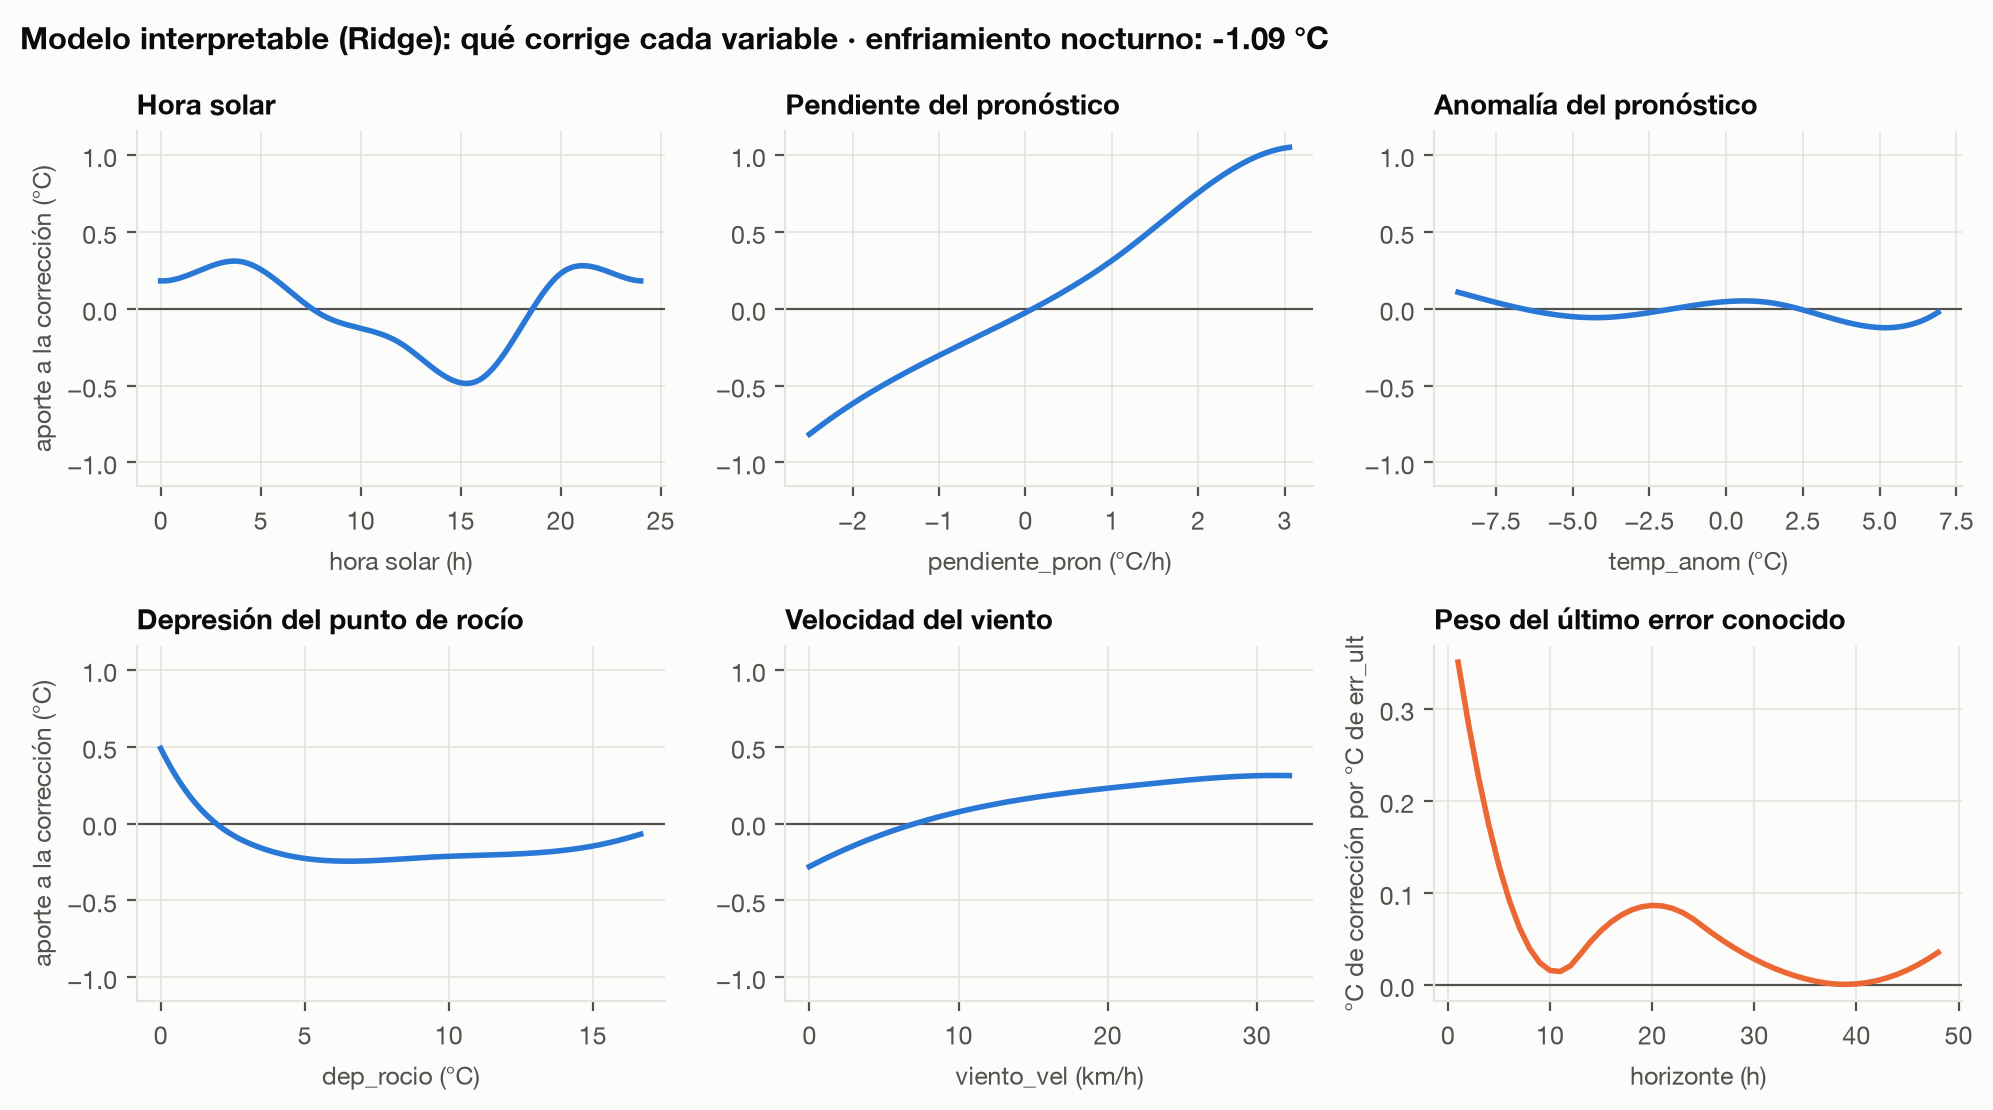

interp_shap_lgbm.png


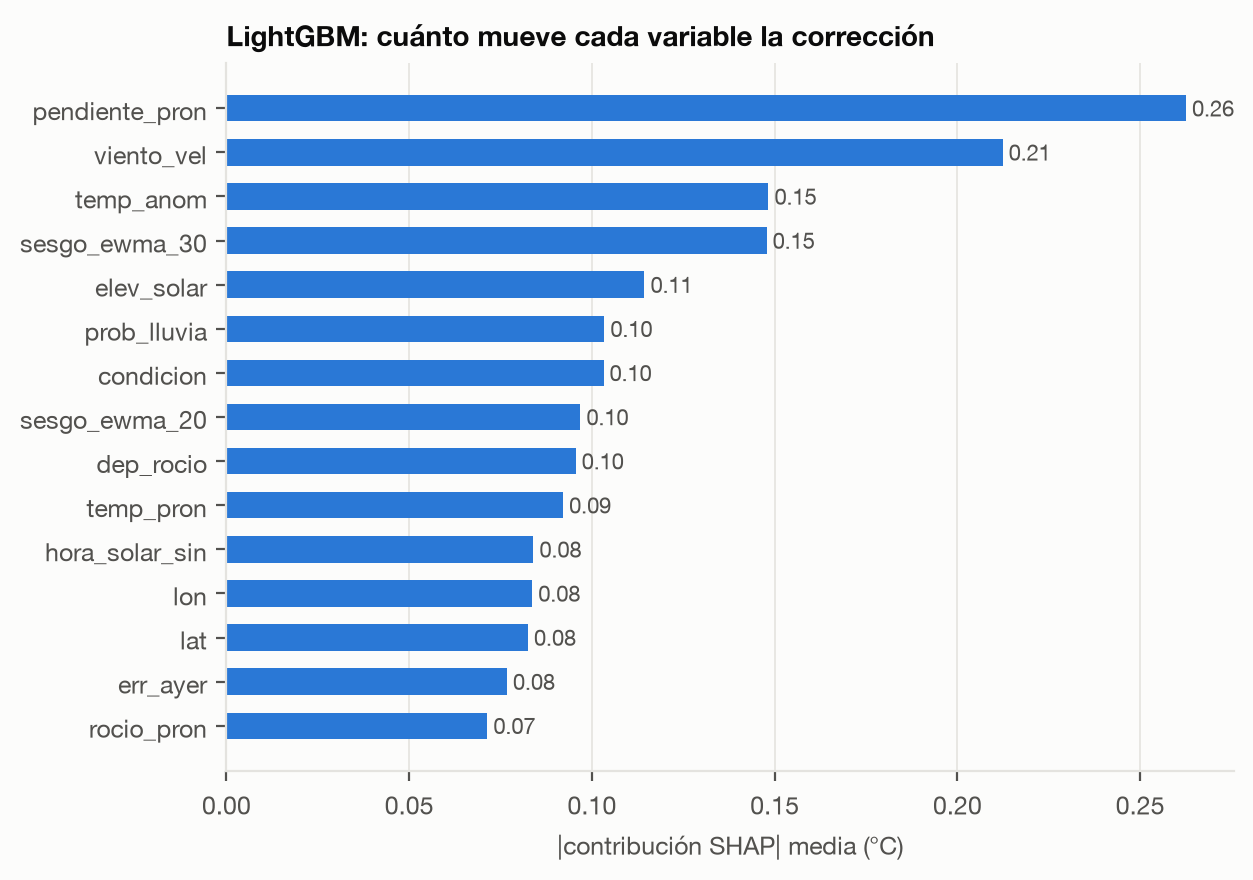

interp_latlon.png


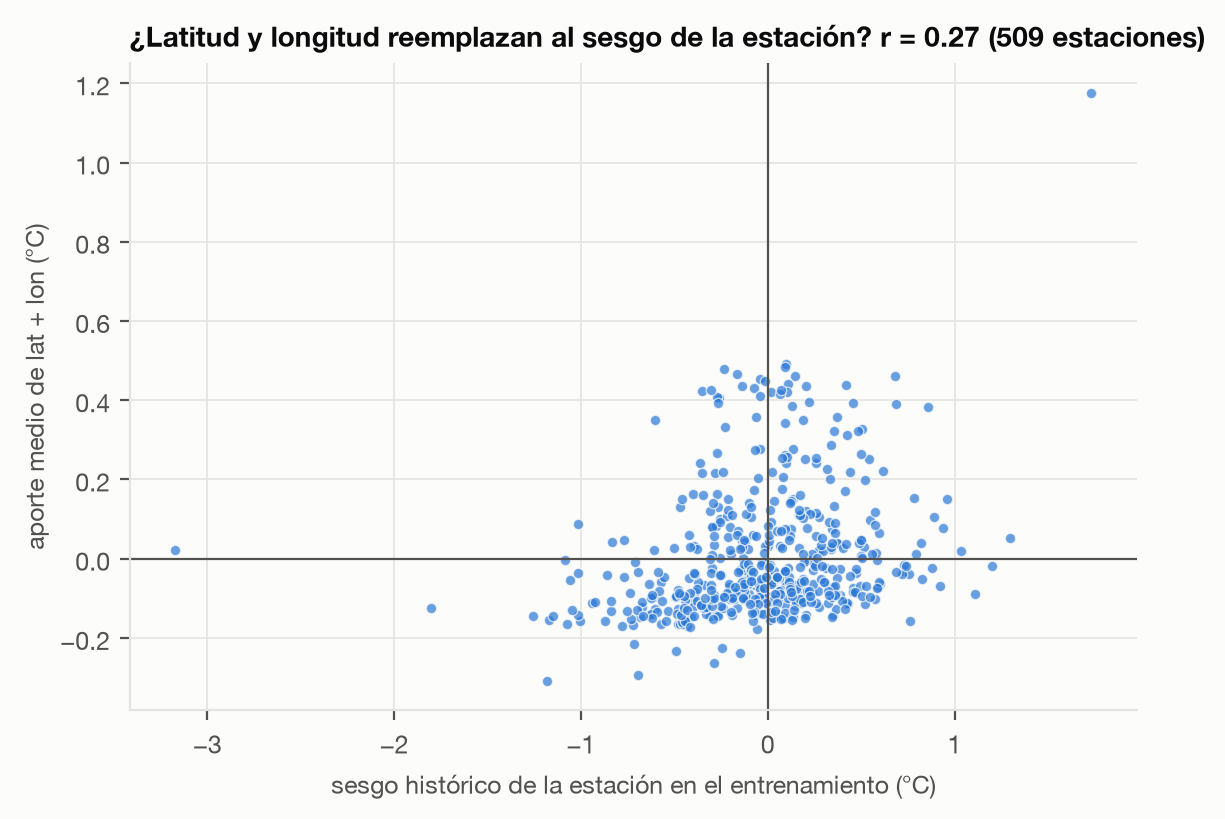

interp_sesgo_hora.png


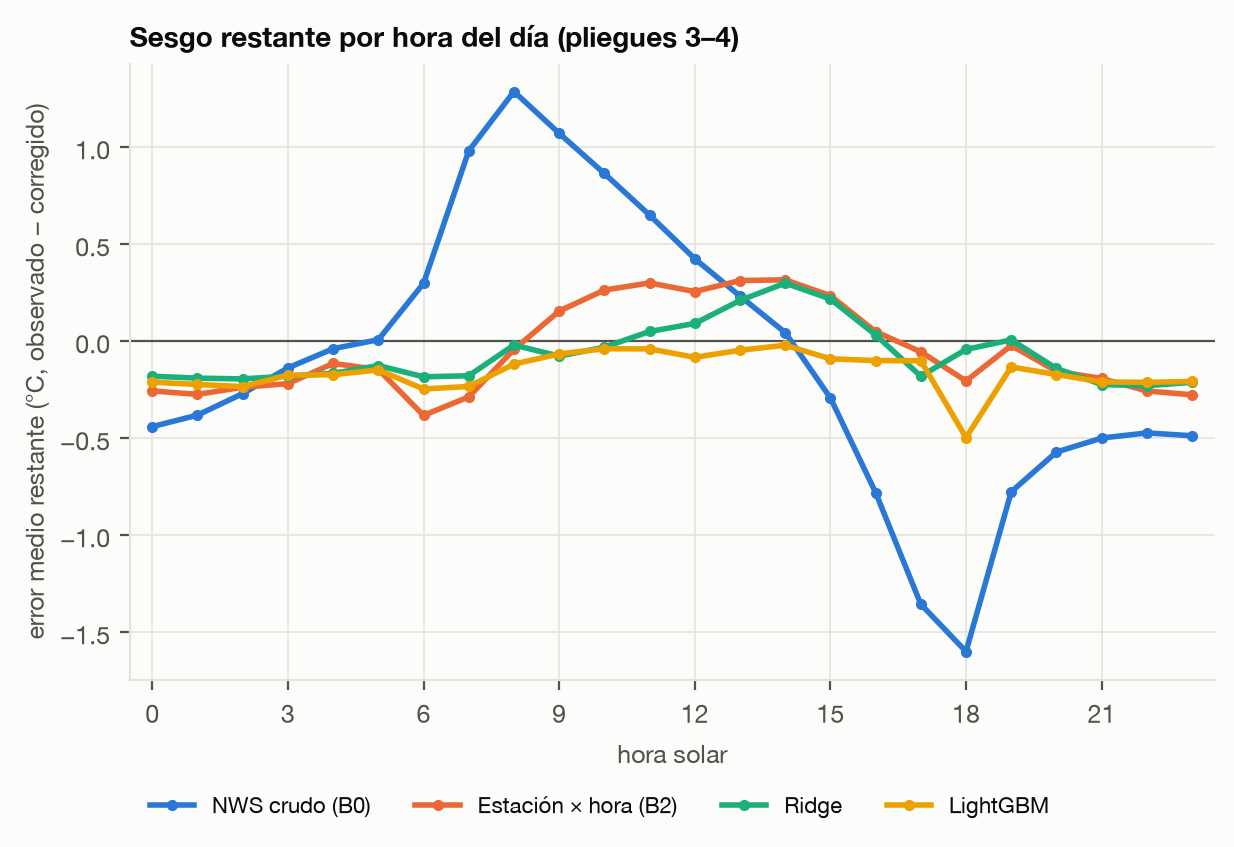

interp_techo.png


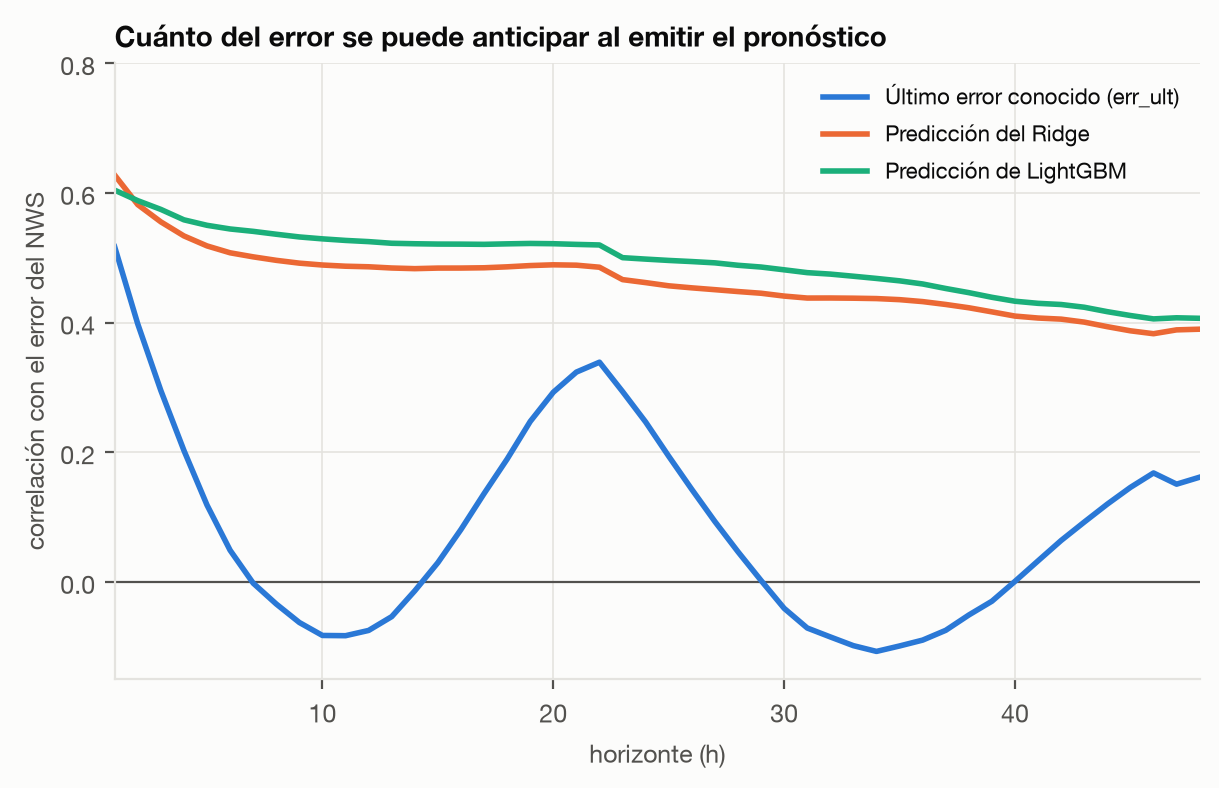

In [13]:
for f in ["interp_curvas_ridge.png", "interp_shap_lgbm.png", "interp_latlon.png", "interp_sesgo_hora.png", "interp_techo.png"]:
    print(f); display(Image(FIG / f, width=850))

## 12. Banda de confianza (la que muestra el dashboard)

Banda P10–P90 del residuo, calibrada en los pliegues 1–2 por tramo de horizonte × condición. Si está bien calibrada,
el 80 % de las observaciones de 3–4 debería caer dentro.

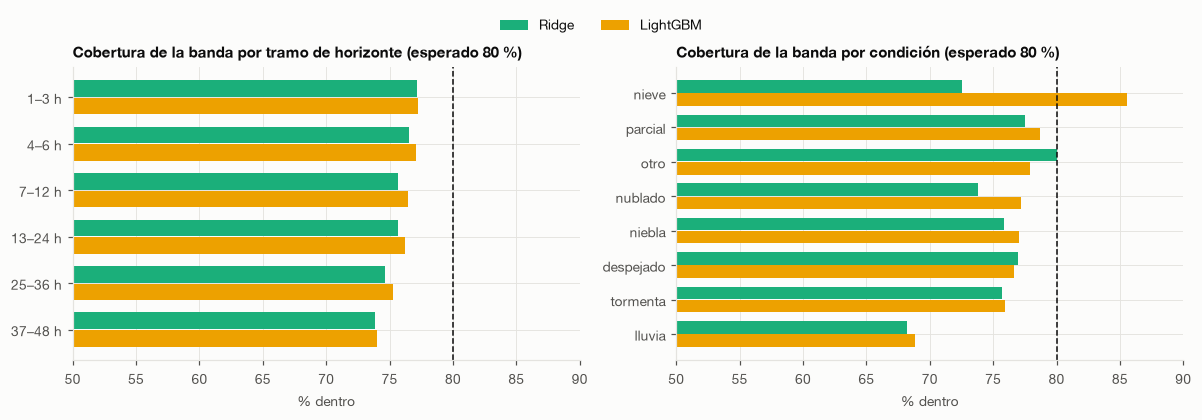

cobertura total: Ridge 75.1 %, LightGBM 75.6 %


In [14]:
BA = pd.read_csv(APP / "bandas.csv")
X = D[["tramo", "condicion", "obs", "lineal", "lgbm"]].astype({"tramo": str, "condicion": str}).merge(BA, on=["tramo", "condicion"], how="left")
for m in ("lineal", "lgbm"):
    X[f"dentro_{m}"] = (X.obs >= X[m] + X[f"{m}_q10"]) & (X.obs <= X[m] + X[f"{m}_q90"])
orden_t = ["1–3 h", "4–6 h", "7–12 h", "13–24 h", "25–36 h", "37–48 h"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for k, col in enumerate(("tramo", "condicion")):
    g = X.groupby(col)[["dentro_lineal", "dentro_lgbm"]].mean() * 100
    g = g.loc[orden_t] if col == "tramo" else g.sort_values("dentro_lgbm", ascending=False)
    y = np.arange(len(g))
    for i, m in enumerate(("lineal", "lgbm")):
        ax[k].barh(y + (i - 0.5) * 0.38, g[f"dentro_{m}"], height=0.36, color=COLOR[m], label=NOMBRE[m])
    ax[k].axvline(80, color=TXT, lw=1, ls="--")
    ax[k].set_yticks(y, g.index)
    ax[k].set(title=f"Cobertura de la banda por {'tramo de horizonte' if col == 'tramo' else 'condición'} (esperado 80 %)",
              xlabel="% dentro", xlim=(50, 90))
    ax[k].invert_yaxis()
fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()
print(f"cobertura total: Ridge {100*X.dentro_lineal.mean():.1f} %, LightGBM {100*X.dentro_lgbm.mean():.1f} %")

**Para criticar:** la banda cubre menos de lo prometido, más a horizontes largos y con lluvia: los pliegues 1–2 fueron
semanas más fáciles que 3–4. Una banda «80 %» que cubre 75 % es optimista; en el informe hay que decirlo así.

## 13. Experimento: errores de las estaciones vecinas

Familia 5 (no está en el producto): error reciente de las 5 estaciones más cercanas a menos de 100 km.
Regla del grupo: una variable que no mejora de forma demostrable el modelo queda como experimento.

In [15]:
V = pd.concat([pd.read_csv(RES / "lgbm_por_pliegue.csv").assign(version="producto"),
               pd.read_csv(RES / "lgbm_por_pliegue_exp_vecinos.csv").assign(version="con vecinos")])
V = (V.query("modelo == 'lgbm' and horizonte in ['todos', '1', '6', '24', '48']")
     .groupby(["segmento", "horizonte", "version"]).apply(lambda g: np.average(g.MAE, weights=g.n), include_groups=False)
     .unstack("version"))
V["diferencia"] = V["con vecinos"] - V["producto"]
display(V)
print("Significancia con vecinos (comparar con la sección 3):")
display(pd.read_csv(RES / "comparacion_significancia_exp_vecinos.csv").query("A == 'lgbm' and B == 'lineal'"))

version               con vecinos  producto  diferencia
segmento   horizonte                                   
completa   1                1.072     1.071       0.000
           24               1.392     1.389       0.003
           48               1.641     1.651      -0.011
           6                1.177     1.177       0.001
           todos            1.381     1.382      -0.002
incompleta 1                1.072     1.102      -0.030
           24               1.239     1.248      -0.009
           48               1.387     1.398      -0.011
           6                1.148     1.174      -0.026
           todos            1.253     1.267      -0.014
todas      1                1.072     1.087      -0.015
           24               1.317     1.320      -0.003
           48               1.508     1.519      -0.011
           6                1.163     1.175      -0.012
           todos            1.317     1.325      -0.008

Significancia con vecinos (comparar con la sección 3):


,segmento,A,B,dias,dif_media_C,IC95_inf,IC95_sup,t,p_valor,dias_gana_A
0,todas,lgbm,lineal,10,-0.034,-0.055,-0.014,-3.163,0.011,9
4,completa,lgbm,lineal,5,-0.021,-0.046,0.008,-1.368,0.243,4
8,incompleta,lgbm,lineal,5,-0.048,-0.078,-0.030,-3.323,0.029,5


## 14. Guía para criticar los modelos

Preguntas que conviene poder responder (y dónde mirar):

1. **¿El modelo complejo se justifica?** LightGBM vs Ridge: diferencia chica y no significativa con historia completa (sección 3). Ridge es casi igual de bueno y mucho más explicable (secciones 9 y 11).
2. **¿Cuánto aporta el ML sobre una tabla de promedios?** Comparar contra B2, no solo contra el NWS (secciones 1 y 2).
3. **¿Dónde no sirve?** Lluvia, algunas estaciones y horizontes largos (secciones 2, 5 y 7).
4. **¿Es confiable fila a fila?** Empeora una fracción grande de filas individuales y la banda cubre menos de lo prometido (secciones 4 y 12).
5. **¿Las conclusiones aguantan?** Solo 10 días de reporte, de otoño, en una región. Sin estacionalidad completa, el modelo no vio invierno ni verano (sección 3).
6. **¿Hay leakage?** Las variables usan el error conocido hasta objetivo − horizonte − 2 h y lo controla `verificar_features.py`. Si alguna métrica parece demasiado buena, sospechar primero de eso.